# Clase 19 · Series temporales
**Ciencia de Datos para Economía y Negocios - FCE-UBA**

Notebook para ir corriendo en clase, celda por celda (en RStudio, Ctrl+Shift+Enter dentro de cada chunk; en Jupyter o Colab, Shift+Enter). La pregunta que ordena la clase: **¿cómo separar, en una serie económica, lo que es señal de lo que es calendario y ruido, y cómo armar series largas y completas?**

1. **La serie y sus componentes**: tendencia, estacionalidad, ciclo y ruido en el EMAE.
2. **Transformaciones estándar**: cambio de base, deflactación, variaciones y log-diferencias.
3. **Promedios móviles**: simples, centrados y exponenciales.
4. **Descomposición**: clásica y STL.
5. **Desestacionalización**: factores estacionales, STL y la comparación con la serie oficial del INDEC.
6. **Empalme de series**: por diferencia, por cociente y por tasas de variación.
7. **Datos faltantes e interpolación**: población intercensal y un hueco artificial en el EMAE.

Cada sección arranca con un recordatorio corto de la teoría (el desarrollo completo está en las diapositivas) y después se pasa al código.

La primera vez hace falta internet: los datos se bajan y quedan guardados en `datos_clase19/`.

**En Google Colab** (versión `.ipynb`): Entorno de ejecución → Cambiar tipo de entorno de ejecución → **R**.

In [1]:
# Paquetes: instala solo los que faltan
paquetes <- c("tidyverse", "zoo", "stinepack")
faltan <- setdiff(paquetes, rownames(installed.packages()))
if (length(faltan) > 0) install.packages(faltan)

suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(zoo)        # rollmean(), na.locf()
  library(stinepack)  # stinterp(): interpolación de Stineman
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110)   # tamaño de gráficos en Jupyter
theme_set(theme_minimal(base_size = 12))

### Datos

Tres series mensuales de la API de series de tiempo de [datos.gob.ar](https://datos.gob.ar/series/api/) y una tabla chica escrita a mano:

| Objeto | Qué es | Período |
|:--|:--|:--|
| `emae` | Estimador Mensual de Actividad Económica (INDEC), base 2004 = 100. Trae la serie original y la desestacionalizada oficial | 2004 en adelante |
| `ipc` | IPC nacional, nivel general (INDEC), base diciembre 2016 = 100 | dic-2016 en adelante |
| `salarios` | Salario medio del empleo privado registrado en la provincia de Buenos Aires (CEP XXI), en pesos corrientes | 2007-2023 |
| `censos` | Población de los censos nacionales (INDEC) | 1869-2022 |

La función `con_cache()` crea el dato la primera vez (bajándolo y limpiándolo) y lo guarda en `datos_clase19/`. Las veces siguientes lo lee de ahí, sin internet.

In [2]:
carpeta_datos <- "datos_clase19"
dir.create(carpeta_datos, showWarnings = FALSE)

con_cache <- function(nombre, crear) {
  archivo <- file.path(carpeta_datos, paste0(nombre, ".rds"))
  if (!file.exists(archivo)) saveRDS(crear(), archivo)
  readRDS(archivo)
}

emae <- con_cache("emae", \() {
  read_csv("https://infra.datos.gob.ar/catalog/sspm/dataset/143/distribution/143.3/download/emae-valores-anuales-indice-base-2004-mensual.csv",
           show_col_types = FALSE) |>
    transmute(fecha = ymd(indice_tiempo),
              emae = emae_original,
              emae_sa_indec = emae_desestacionalizada)
})

ipc <- con_cache("ipc", \() {
  read_csv("https://infra.datos.gob.ar/catalog/sspm/dataset/145/distribution/145.3/download/indice-precios-al-consumidor-nivel-general-base-diciembre-2016-mensual.csv",
           show_col_types = FALSE) |>
    transmute(fecha = ymd(indice_tiempo), ipc = ipc_ng_nacional)
})

salarios <- con_cache("salarios_pba", \() {
  read_csv("https://cdn.produccion.gob.ar/cdn-cep/datos-por-provincia/por-provincia/salarios/w_mean_priv.csv",
           show_col_types = FALSE) |>
    filter(zona_prov == "BUENOS AIRES") |>
    transmute(fecha = ymd(fecha), salario = w_mean)
})

censos <- tibble(
  anio = c(1869, 1895, 1914, 1947, 1960, 1970, 1980, 1991, 2001, 2010, 2022),
  poblacion = c(1877490, 4044911, 7903662, 15893827, 20013793, 23364431,
                27949480, 32615528, 36260130, 40117096, 46044703)
)

glimpse(emae)
glimpse(ipc)
glimpse(salarios)

Rows: 271
Columns: 3
$ fecha         <date> 2004-01-01, 2004-02-01, 2004-03-01, 2004-04-01, 2004-05…
$ emae          <dbl> 92.62751, 90.18618, 101.88330, 102.56743, 109.87750, 105…
$ emae_sa_indec <dbl> 98.53181, 98.02704, 97.51833, 95.45367, 96.92321, 98.513…
Rows: 118
Columns: 2
$ fecha <date> 2016-12-01, 2017-01-01, 2017-02-01, 2017-03-01, 2017-04-01, 201…
$ ipc   <dbl> 100.0000, 101.5859, 103.6859, 106.1476, 108.9667, 110.5301, 111.…
Rows: 203
Columns: 2
$ fecha   <date> 2007-01-01, 2007-02-01, 2007-03-01, 2007-04-01, 2007-05-01, 2…
$ salario <dbl> 1777, 1693, 1779, 1773, 1813, 2611, 1871, 1901, 1914, 1988, 19…


# Parte 1. La serie y sus componentes

## 1.1 Mirar la serie

Una **serie temporal** es una secuencia de observaciones ordenadas en el tiempo. A diferencia de un corte transversal, el **orden importa**: cada valor depende de los anteriores, así que las filas no se pueden mezclar.

Una serie se piensa como la combinación de cuatro piezas:

| Componente | Qué es |
|:--|:--|
| Tendencia ($T$) | Dirección de largo plazo |
| Estacionalidad ($S$) | Patrón que se repite con el calendario (cada 12 meses, cada 4 trimestres) |
| Ciclo ($C$) | Fluctuaciones de mediano plazo **sin** frecuencia fija (recesiones, expansiones) |
| Ruido ($I$) | Lo irregular, lo que no explican los anteriores |

En la práctica $T$ y $C$ se estiman juntos como **ciclo-tendencia**.

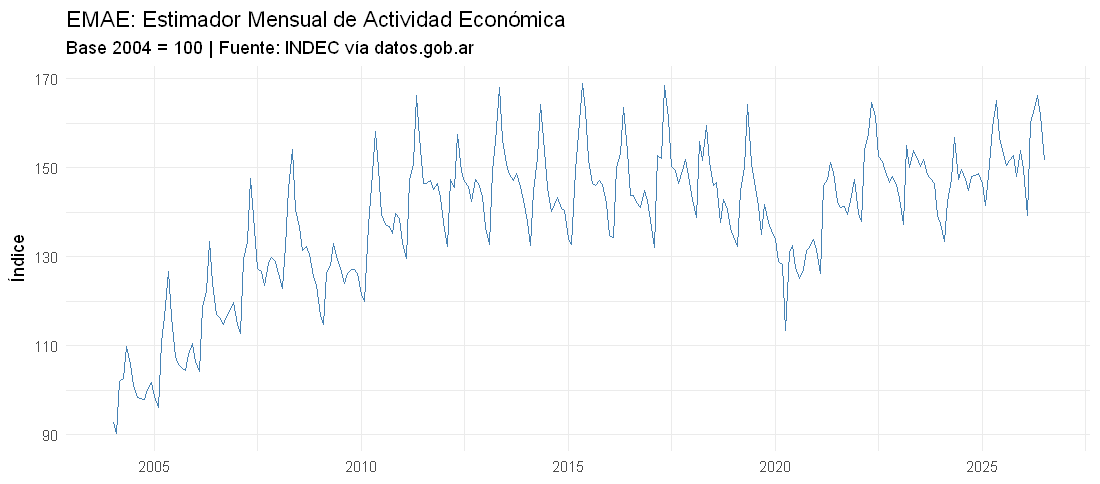

In [3]:
options(repr.plot.height = 4.4)
ggplot(emae, aes(fecha, emae)) +
  geom_line(color = "steelblue", linewidth = 0.5) +
  labs(title = "EMAE: Estimador Mensual de Actividad Económica",
       subtitle = "Base 2004 = 100 | Fuente: INDEC vía datos.gob.ar",
       x = NULL, y = "Índice")

> 💡 **Lectura.** Se ven las cuatro piezas a simple vista: una **tendencia** creciente hasta 2011 y casi plana después; **ciclos** con caídas en 2009, 2014, 2016, 2018-2019 y el pozo de abril de 2020; una **estacionalidad** que hace serrucho todos los años; y **ruido** mes a mes.

## 1.2 El objeto `ts()`

R tiene una clase propia para series temporales. Además de los valores, guarda la **fecha de inicio** y la **frecuencia**, es decir, el período estacional $s$: 12 para datos mensuales, 4 para trimestrales, 7 para diarios con patrón semanal. Las funciones de descomposición (`decompose()`, `stl()`) necesitan este objeto.

In [4]:
emae_ts <- ts(emae$emae,
              start = c(year(min(emae$fecha)), month(min(emae$fecha))),
              frequency = 12)

window(emae_ts, start = c(2004, 1), end = c(2005, 12))
frequency(emae_ts)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2004,92.62751,90.18618,101.88330,102.56743,109.87750,105.66241,101.10700,98.35574,98.08637,97.83567,100.13195,101.67895
2005,98.47336,96.11887,110.65643,116.54519,126.66194,116.50222,107.58114,105.82089,104.89213,104.46067,108.00375,110.50332


[1] 12

> ⚠️ **Atención.** `ts()` no mira las fechas: asume que los datos están ordenados y **sin huecos ni duplicados**. Si falta un mes, todo lo que viene después queda corrido un lugar y el "enero" pasa a ser "febrero". Antes de armar el `ts()` conviene ordenar por fecha y chequear que no falte ningún período.

In [5]:
# Chequeo de regularidad: ¿hay algún salto distinto de un mes entre filas?
emae |>
  arrange(fecha) |>
  mutate(salto = interval(lag(fecha), fecha) %/% months(1)) |>
  count(salto)

salto,n
<dbl>,<int>
1,270
NA,1


## 1.3 ¿Aditiva o multiplicativa?

Hay dos formas de combinar los componentes:

$$\text{Aditiva: } Y_t = T_t + S_t + I_t \qquad\qquad \text{Multiplicativa: } Y_t = T_t \times S_t \times I_t$$

En la aditiva la oscilación estacional tiene **siempre el mismo tamaño** en unidades; en la multiplicativa es un **porcentaje** del nivel, así que crece cuando la serie sube. Tomar logaritmos convierte una en la otra: $\log Y_t = \log T_t + \log S_t + \log I_t$.

Una forma rápida de verlo: graficar cada año como una línea, con los meses en el eje horizontal.

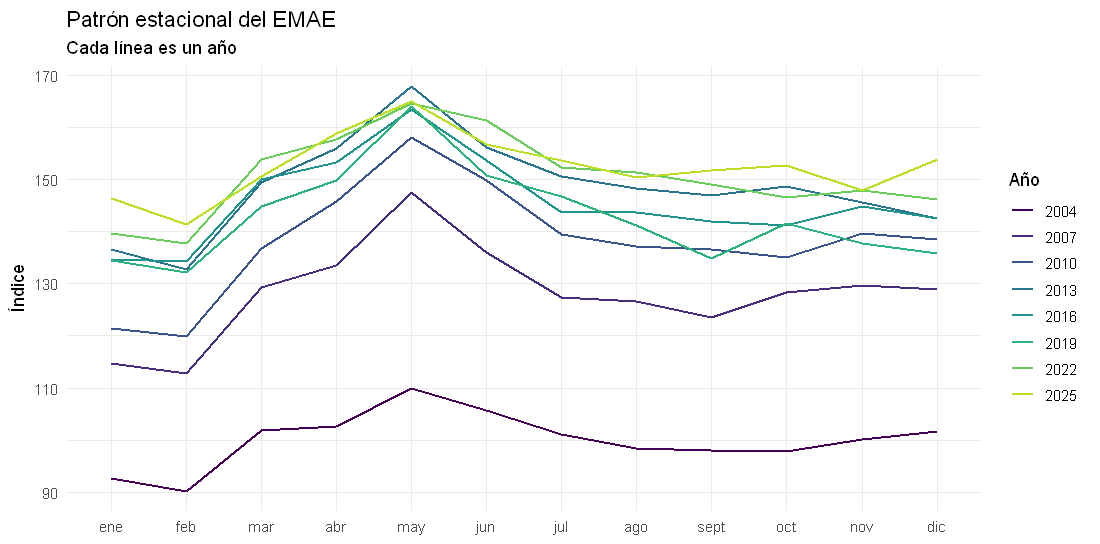

In [6]:
options(repr.plot.height = 4.95)
emae |>
  mutate(anio = year(fecha), mes = month(fecha, label = TRUE)) |>
  filter(anio %in% c(2004, 2007, 2010, 2013, 2016, 2019, 2022, 2025)) |>
  ggplot(aes(mes, emae, group = anio, color = factor(anio))) +
  geom_line(linewidth = 0.7) +
  scale_color_viridis_d(end = 0.9) +
  labs(title = "Patrón estacional del EMAE",
       subtitle = "Cada línea es un año",
       x = NULL, y = "Índice", color = "Año")

In [7]:
# Amplitud estacional de cada año: en puntos del índice y en % del promedio anual
emae |>
  mutate(anio = year(fecha)) |>
  filter(anio %in% c(2004, 2010, 2016, 2022, 2025)) |>
  group_by(anio) |>
  summarise(promedio = mean(emae),
            amplitud_puntos = max(emae) - min(emae),
            amplitud_pct = amplitud_puntos / promedio * 100)

anio,promedio,amplitud_puntos,amplitud_pct
<dbl>,<dbl>,<dbl>,<dbl>
2004,100.0000,19.69132,19.69132
2010,138.2195,38.28783,27.70075
2016,145.6309,29.28125,20.10647
2022,150.7563,26.83985,17.80347
2025,152.4852,23.66994,15.52278


> 💡 **Lectura.** El valle de enero-febrero y el pico de abril-mayo (la cosecha gruesa) se repiten todos los años. Entre 2004 y 2010 el nivel subió 38% y la amplitud estacional casi se duplicó en puntos (de 20 a 38): la estacionalidad acompañó al nivel, como en una estructura **multiplicativa**, que es lo habitual en series de cantidades. Después la amplitud se fue achicando, tanto en puntos como en porcentaje (de 28% en 2010 a 16% en 2025): el patrón estacional **no es fijo**, y eso va a importar al elegir el método de descomposición.

# Parte 2. Transformaciones estándar

## 2.1 Indexación y cambio de base

Un número índice expresa cada valor como proporción de un período de referencia:

$$I_t = \frac{X_t}{X_{\text{base}}} \times 100$$

Para **cambiar la base** de un índice al período $t_1$ alcanza con dividir todo por el valor de ese período y multiplicar por 100. El cambio de base mueve el nivel de referencia pero **no** cambia la dinámica: las variaciones porcentuales quedan iguales.

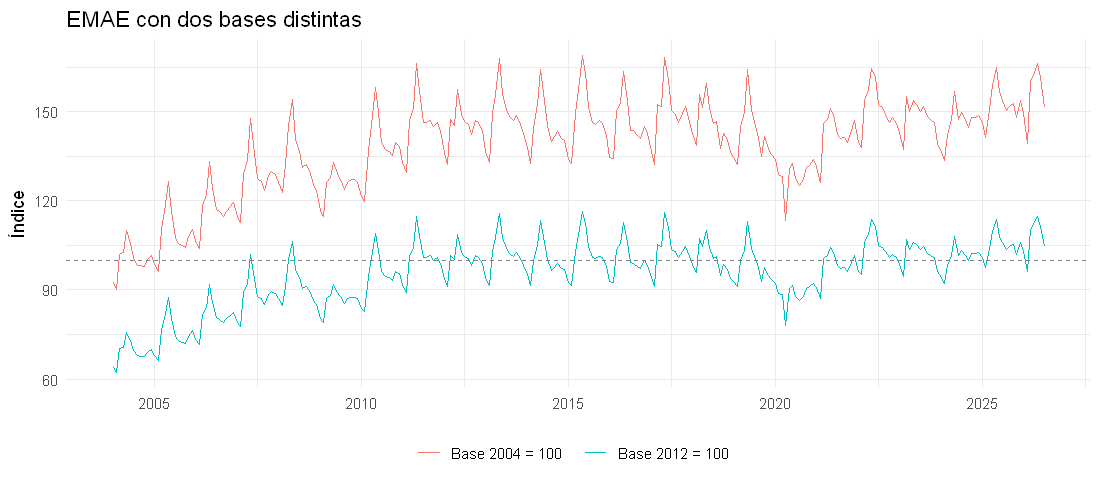

In [8]:
options(repr.plot.height = 4.4)
base_2012 <- emae |> filter(year(fecha) == 2012) |> summarise(mean(emae)) |> pull()

emae <- emae |> mutate(emae_base2012 = emae / base_2012 * 100)

emae |>
  select(fecha, `Base 2004 = 100` = emae, `Base 2012 = 100` = emae_base2012) |>
  pivot_longer(-fecha, names_to = "base", values_to = "valor") |>
  ggplot(aes(fecha, valor, color = base)) +
  geom_line(linewidth = 0.5) +
  geom_hline(yintercept = 100, linetype = "dashed", color = "grey50") +
  labs(title = "EMAE con dos bases distintas",
       x = NULL, y = "Índice", color = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** Con base en el promedio de 2012, la actividad de 2004 queda en 69 y la de 2025 en 105: entre 2004 y 2025 la economía creció un 52%, y desde 2012 apenas un 5%. Usamos como base el **promedio de un año** y no un mes suelto porque un mes trae su estacionalidad.

## 2.2 Deflactación

Una variable en **pesos corrientes** mezcla dos cosas: cambios en cantidades (o en poder de compra) y cambios en precios. Para quedarnos con lo real se **deflacta** con un índice de precios:

$$X_t^{\text{real}} = \frac{X_t^{\text{nominal}}}{\text{Deflactor}_t} \times 100$$

Para salarios e ingresos de los hogares el deflactor natural es el **IPC**. Como el IPC tiene base diciembre 2016 = 100, el salario real queda expresado **en pesos de diciembre de 2016**.

In [9]:
salario_real <- salarios |>
  inner_join(ipc, by = "fecha") |>
  mutate(real = salario / ipc * 100)

head(salario_real, 3)
tail(salario_real, 3)

fecha,salario,ipc,real
<date>,<dbl>,<dbl>,<dbl>
2016-12-01,30478,100.0000,30478.00
2017-01-01,22282,101.5859,21934.15
2017-02-01,21328,103.6859,20569.82


fecha,salario,ipc,real
<date>,<dbl>,<dbl>,<dbl>
2023-09-01,420078,2304.924,18225.24
2023-10-01,459722,2496.273,18416.34
2023-11-01,508793,2816.063,18067.53


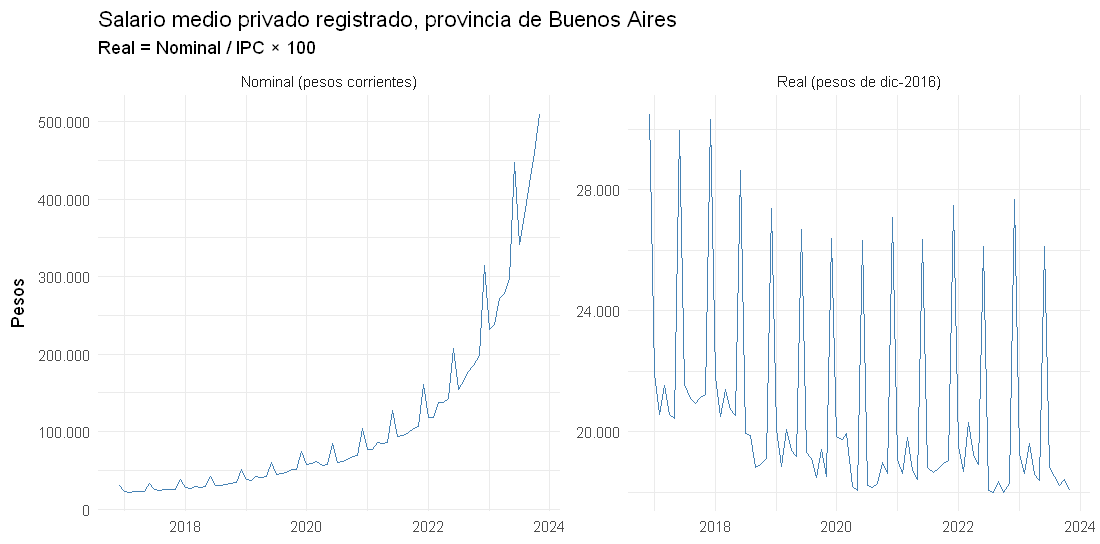

In [10]:
options(repr.plot.height = 4.95)
salario_real |>
  select(fecha, `Nominal (pesos corrientes)` = salario,
         `Real (pesos de dic-2016)` = real) |>
  pivot_longer(-fecha, names_to = "serie", values_to = "valor") |>
  ggplot(aes(fecha, valor)) +
  geom_line(color = "steelblue", linewidth = 0.6) +
  facet_wrap(~serie, scales = "free_y") +
  scale_y_continuous(labels = scales::label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "Salario medio privado registrado, provincia de Buenos Aires",
       subtitle = "Real = Nominal / IPC × 100",
       x = NULL, y = "Pesos")

> 💡 **Lectura.** En pesos corrientes el salario se multiplicó por casi 23 entre enero de 2017 (22.282 pesos) y noviembre de 2023 (508.793), pero eso es casi todo inflación. En pesos de diciembre de 2016 pasó de 21.934 a 18.068: una caída real del 18%. Los picos de junio y diciembre son el **aguinaldo** (por eso diciembre de 2016 arranca en 30.478): el salario también tiene estacionalidad.

> ⚠️ **Atención.** El deflactor tiene que tener la **misma frecuencia y el mismo período** que la serie a deflactar (por eso el `inner_join()`), y tiene que ser coherente con lo que se mide: IPC para ingresos de hogares, índices de precios mayoristas para costos de producción, deflactor del PBI para agregados macro.

## 2.3 Variaciones y log-diferencias

| Medida | Fórmula | Para qué |
|:--|:--|:--|
| Variación mensual | $\dfrac{X_t - X_{t-1}}{X_{t-1}} \times 100$ | Dinámica de corto plazo (pero arrastra la estacionalidad) |
| Variación interanual | $\dfrac{X_t - X_{t-12}}{X_{t-12}} \times 100$ | Compara el mismo mes de años distintos: **neutraliza** la estacionalidad |
| Log-diferencia | $(\log X_t - \log X_{t-1}) \times 100$ | Aproxima la variación %; es aditiva y simétrica |

En R, `lag(x, k)` corre la serie `k` lugares: `lag(emae)` es el mes anterior y `lag(emae, 12)` el mismo mes del año anterior. Por eso **los datos tienen que estar ordenados por fecha**.

In [11]:
emae <- emae |>
  arrange(fecha) |>
  mutate(var_mensual    = (emae / lag(emae) - 1) * 100,
         var_interanual = (emae / lag(emae, 12) - 1) * 100,
         logdif_mensual = (log(emae) - log(lag(emae))) * 100)

emae |>
  filter(fecha >= "2020-01-01", fecha <= "2020-06-01") |>
  select(fecha, emae, var_mensual, var_interanual, logdif_mensual)

fecha,emae,var_mensual,var_interanual,logdif_mensual
<date>,<dbl>,<dbl>,<dbl>,<dbl>
2020-01-01,133.8911,-1.3803751,-0.479539,-1.3899909
2020-02-01,128.9736,-3.6727220,-2.490589,-3.7418646
2020-03-01,128.2111,-0.5912666,-11.556166,-0.5930215
2020-04-01,113.2950,-11.6339622,-24.427768,-12.3682478
2020-05-01,131.0296,15.6534087,-20.169975,14.5427676
2020-06-01,132.5220,1.1389766,-12.155065,1.1325390


> 💡 **Lectura.** En abril de 2020 el EMAE cayó 11,6% contra marzo y 24,4% contra abril de 2019. La log-diferencia da −12,4 en abril y +14,5 en mayo, contra −11,6% y +15,7% de la variación simple: para cambios tan grandes ya **no** es una buena aproximación. En meses normales, con cambios de 1% o 2%, las dos medidas son casi iguales. Notar también la asimetría de la variación simple: cae 11,6% y sube 15,7%, y apenas recupera el nivel de marzo.

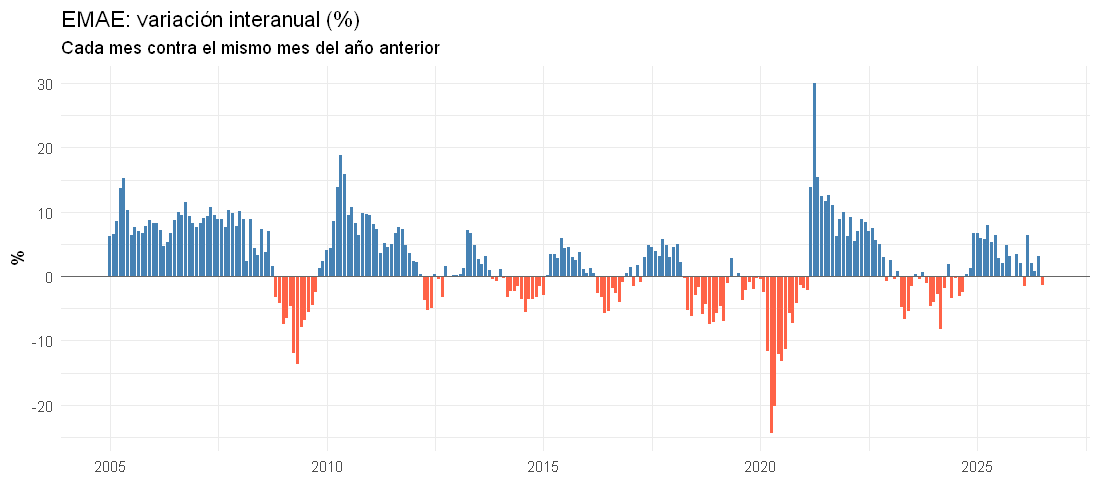

In [12]:
options(repr.plot.height = 4.4)
emae |>
  filter(!is.na(var_interanual)) |>
  ggplot(aes(fecha, var_interanual)) +
  geom_col(aes(fill = var_interanual > 0), show.legend = FALSE) +
  geom_hline(yintercept = 0, color = "grey40") +
  scale_fill_manual(values = c("tomato", "steelblue")) +
  labs(title = "EMAE: variación interanual (%)",
       subtitle = "Cada mes contra el mismo mes del año anterior",
       x = NULL, y = "%")

### Las variaciones no se suman

Una trampa frecuente: sumar las variaciones mensuales para obtener la del año. Lo correcto es **multiplicar** los factores $(1 + r_1)(1 + r_2)\cdots(1 + r_{12})$. Las log-diferencias, en cambio, sí se suman.

In [13]:
anio_2023 <- emae |> filter(fecha >= "2023-01-01", fecha <= "2023-12-01")

tibble(
  `Suma de variaciones mensuales` = sum(anio_2023$var_mensual),
  `Producto de (1 + r) - 1`       = (prod(1 + anio_2023$var_mensual / 100) - 1) * 100,
  `Variación dic-23 vs dic-22`    = anio_2023$var_interanual[12],
  `Suma de log-diferencias`       = sum(anio_2023$logdif_mensual),
  `Log de dic-23 menos dic-22`    = (log(anio_2023$emae[12]) - log(emae$emae[emae$fecha == "2022-12-01"])) * 100
)

Suma de variaciones mensuales,Producto de (1 + r) - 1,Variación dic-23 vs dic-22,Suma de log-diferencias,Log de dic-23 menos dic-22
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
-3.652407,-4.677891,-4.677891,-4.790841,-4.790841


> 💡 **Lectura.** Sumando las doce variaciones mensuales de 2023 da −3,7%, pero la variación real entre diciembre de 2022 y diciembre de 2023 fue −4,7%, lo mismo que el producto de los factores. La suma de log-diferencias, en cambio, coincide exactamente con la log-diferencia punta a punta (−4,8). Esa propiedad es la que las hace tan cómodas en economía.

# Parte 3. Promedios móviles

## 3.1 Promedio móvil simple: trailing y centrado

El promedio móvil de orden $k$ promedia $k$ observaciones vecinas:

$$MA_t^{(k)} = \frac{1}{k}\sum_{j=0}^{k-1} X_{t-j}$$

- **Trailing** (`align = "right"`): usa el dato de hoy y los $k-1$ anteriores. Se puede calcular en tiempo real, pero **llega tarde** a los cambios.
- **Centrado** (`align = "center"`): toma la mitad de las observaciones antes y la mitad después. Está bien ubicado en el tiempo, pero no se puede calcular en los extremos.

Si $k$ es igual al período estacional (12 en una serie mensual), cada promedio contiene exactamente un enero, un febrero, etc.: la estacionalidad **desaparece** y queda una estimación de la ciclo-tendencia.

In [14]:
emae <- emae |>
  mutate(ma3       = rollmean(emae, k = 3,  fill = NA, align = "center"),
         ma12      = rollmean(emae, k = 12, fill = NA, align = "center"),
         ma12_trail = rollmean(emae, k = 12, fill = NA, align = "right"))

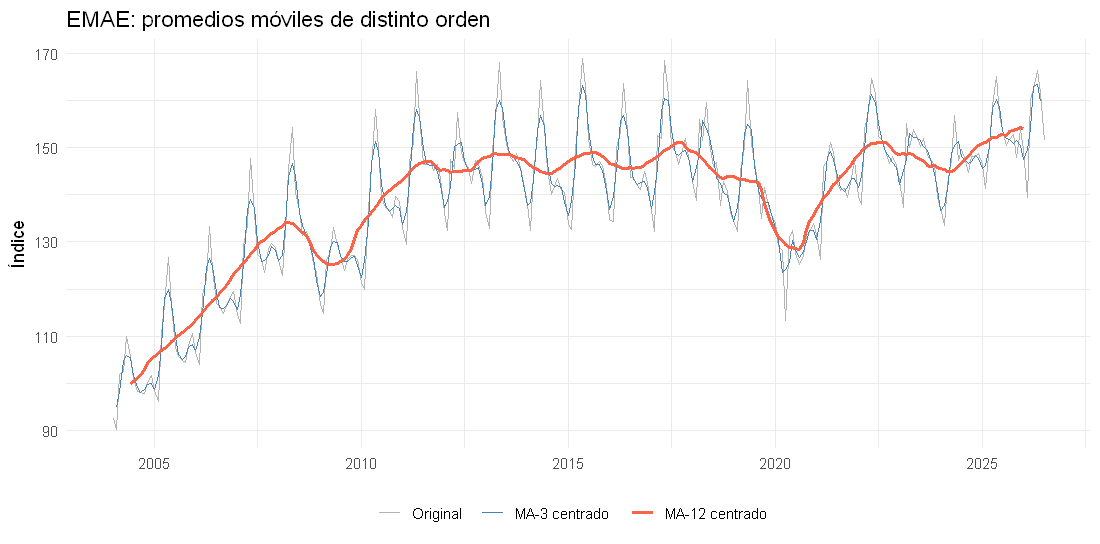

In [15]:
options(repr.plot.height = 4.95)
emae |>
  select(fecha, Original = emae, `MA-3 centrado` = ma3, `MA-12 centrado` = ma12) |>
  pivot_longer(-fecha, names_to = "serie", values_to = "valor") |>
  mutate(serie = fct_inorder(serie)) |>
  ggplot(aes(fecha, valor, color = serie, linewidth = serie)) +
  geom_line(na.rm = TRUE) +
  scale_color_manual(values = c("grey70", "steelblue", "tomato")) +
  scale_linewidth_manual(values = c(0.3, 0.6, 1)) +
  labs(title = "EMAE: promedios móviles de distinto orden",
       x = NULL, y = "Índice", color = NULL, linewidth = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** El MA-3 suaviza el ruido pero conserva el serrucho estacional. El MA-12 se lo saca entero y deja una línea que se lee como ciclo-tendencia: el estancamiento desde 2011, las recesiones y la recuperación de 2021.

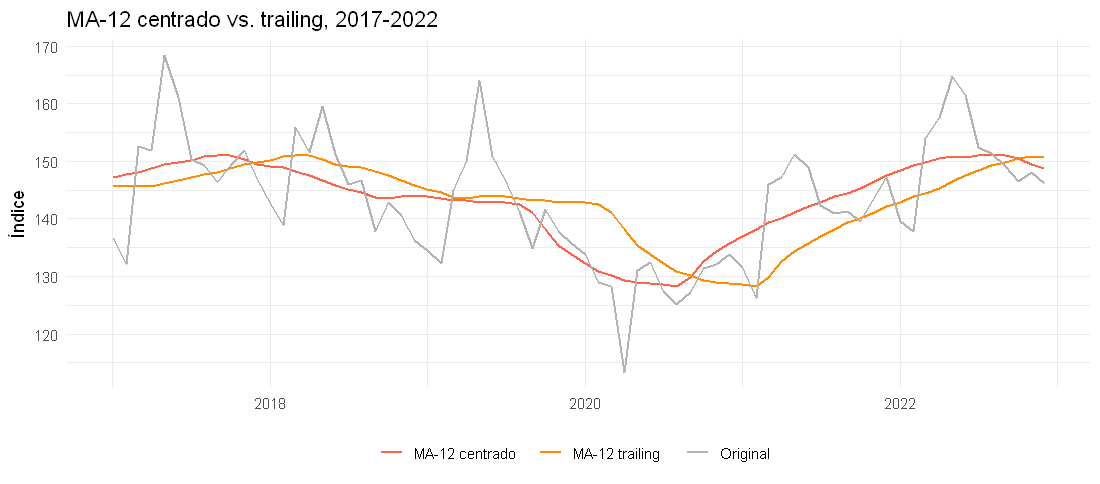

In [16]:
options(repr.plot.height = 4.4)
emae |>
  filter(fecha >= "2017-01-01", fecha <= "2022-12-01") |>
  select(fecha, Original = emae, `MA-12 centrado` = ma12, `MA-12 trailing` = ma12_trail) |>
  pivot_longer(-fecha, names_to = "serie", values_to = "valor") |>
  ggplot(aes(fecha, valor, color = serie)) +
  geom_line(linewidth = 0.8, na.rm = TRUE) +
  scale_color_manual(values = c("tomato", "darkorange", "grey70")) +
  labs(title = "MA-12 centrado vs. trailing, 2017-2022",
       x = NULL, y = "Índice", color = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** El trailing marca el piso de la pandemia recién a comienzos de 2021, unos seis meses después del centrado. Es el costo de no usar datos futuros: el promedio de los últimos 12 meses va **atrasado** medio año. Sirve para monitorear en tiempo real ("actividad de los últimos 12 meses"), no para fechar puntos de giro.

## 3.2 Promedio móvil exponencial

El promedio móvil exponencial (EMA) se actualiza en forma recursiva:

$$EMA_t = \alpha \, X_t + (1 - \alpha)\, EMA_{t-1}, \qquad \alpha \in (0, 1)$$

Cada dato nuevo entra con peso $\alpha$ y el pasado se va olvidando de a poco: el peso de una observación de hace $j$ períodos es $\alpha (1-\alpha)^j$. Con $\alpha$ alto sigue de cerca al dato; con $\alpha$ bajo suaviza más. Como la fórmula se define con el valor anterior, la programamos con un `for`.

In [17]:
ema <- function(x, alpha) {
  salida <- numeric(length(x))
  salida[1] <- x[1]
  for (t in 2:length(x)) {
    salida[t] <- alpha * x[t] + (1 - alpha) * salida[t - 1]
  }
  salida
}

emae <- emae |>
  mutate(ema_rapido = ema(emae, alpha = 0.5),
         ema_lento  = ema(emae, alpha = 0.15))

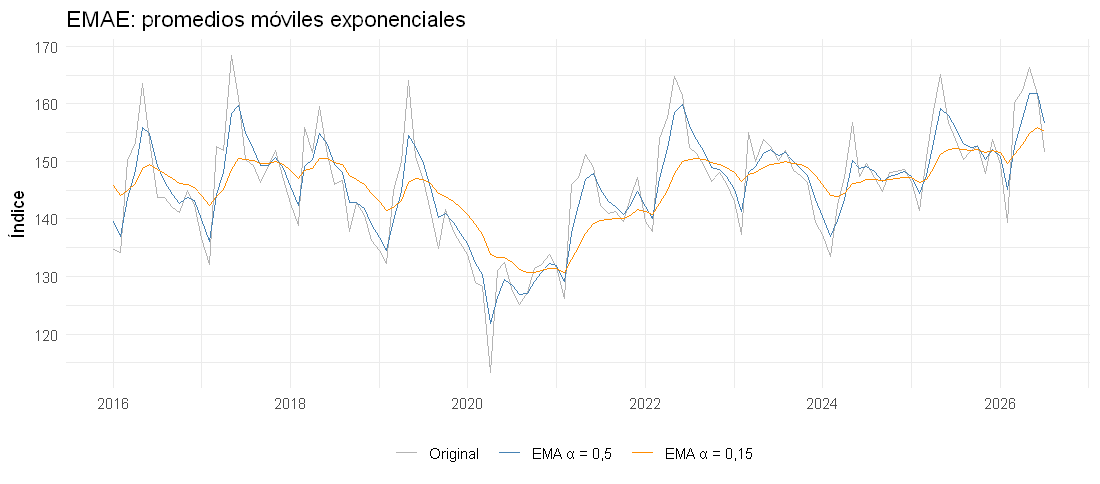

In [18]:
options(repr.plot.height = 4.4)
emae |>
  filter(fecha >= "2016-01-01") |>
  select(fecha, Original = emae, `EMA α = 0,5` = ema_rapido, `EMA α = 0,15` = ema_lento) |>
  pivot_longer(-fecha, names_to = "serie", values_to = "valor") |>
  mutate(serie = fct_inorder(serie)) |>
  ggplot(aes(fecha, valor, color = serie)) +
  geom_line(linewidth = 0.6) +
  scale_color_manual(values = c("grey70", "steelblue", "darkorange")) +
  labs(title = "EMAE: promedios móviles exponenciales",
       x = NULL, y = "Índice", color = NULL) +
  theme(legend.position = "bottom")

> ⚠️ **Atención.** El EMA es un filtro hacia atrás: igual que el trailing, **reacciona con retraso**. Con $\alpha = 0,15$ el pozo de abril de 2020 casi desaparece y el piso queda corrido hacia fines de año. Además, no elimina la estacionalidad: ningún valor de $\alpha$ promedia exactamente un ciclo de 12 meses. El paquete `TTR` tiene una versión lista, `TTR::EMA(x, n = ...)`, con $\alpha = 2 / (n + 1)$.

# Parte 4. Descomposición

## 4.1 Descomposición clásica

Es el algoritmo más simple para separar los componentes:

1. Estimar la tendencia $\hat T_t$ con un promedio móvil centrado de orden $s$ (el MA-12 de arriba).
2. Sacársela a la serie: $Y_t - \hat T_t$ (aditiva) o $Y_t / \hat T_t$ (multiplicativa).
3. Promediar ese resultado para cada mes (todos los eneros, todos los febreros...): eso es el factor estacional $\hat S$.
4. Lo que sobra es el residuo: $\hat I_t = Y_t - \hat T_t - \hat S_t$ (o $Y_t / (\hat T_t \hat S_t)$).

En R lo hace `decompose()`. Para graficar los componentes con ggplot armamos una función que los pase a formato largo.

In [19]:
desc_aditiva <- decompose(emae_ts, type = "additive")
desc_mult    <- decompose(emae_ts, type = "multiplicative")

graficar_componentes <- function(fecha, observada, tendencia, estacional, residuo, titulo) {
  tibble(fecha, observada, tendencia, estacional, residuo) |>
    pivot_longer(-fecha, names_to = "componente", values_to = "valor") |>
    mutate(componente = factor(componente,
      levels = c("observada", "tendencia", "estacional", "residuo"),
      labels = c("Serie observada", "Tendencia", "Estacionalidad", "Residuo"))) |>
    ggplot(aes(fecha, valor)) +
    geom_line(color = "steelblue", linewidth = 0.4, na.rm = TRUE) +
    facet_wrap(~componente, scales = "free_y", ncol = 1) +
    labs(title = titulo, x = NULL, y = NULL)
}

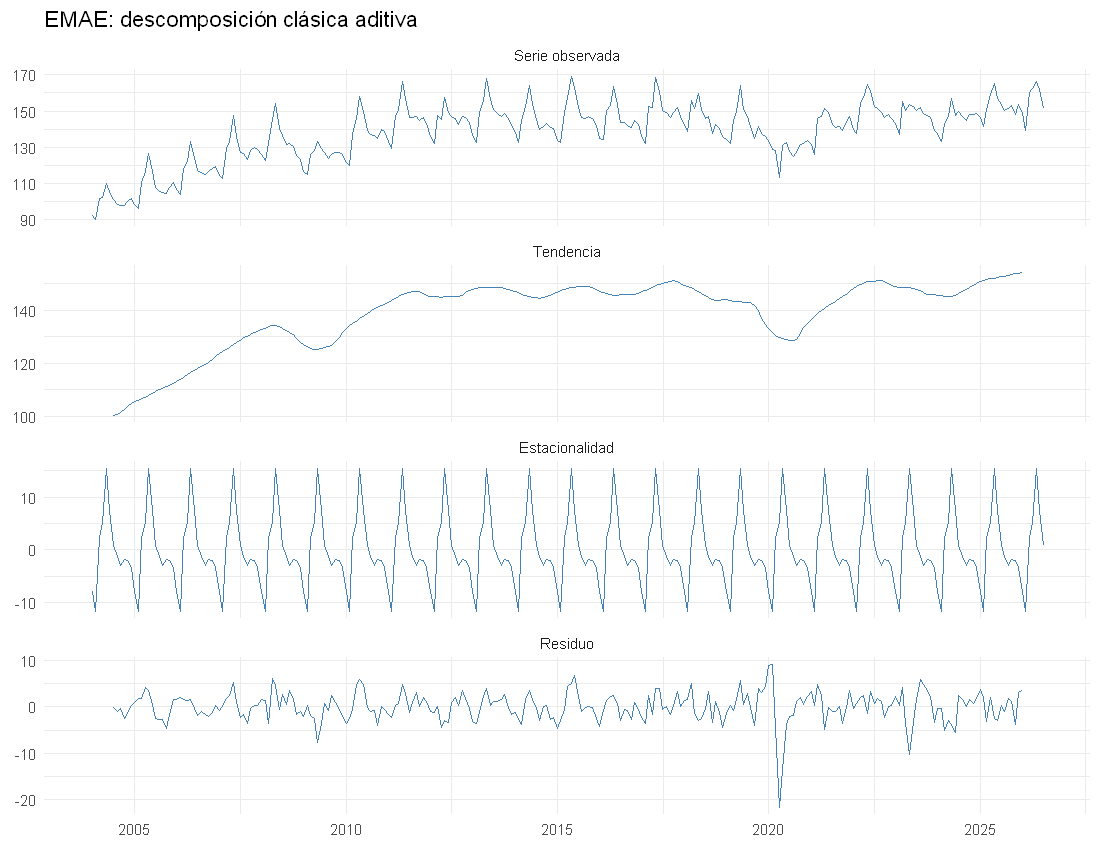

In [20]:
options(repr.plot.height = 7.7)
graficar_componentes(emae$fecha,
                     as.numeric(emae_ts),
                     as.numeric(desc_aditiva$trend),
                     as.numeric(desc_aditiva$seasonal),
                     as.numeric(desc_aditiva$random),
                     "EMAE: descomposición clásica aditiva")

In [21]:
# Factores estacionales de cada versión (son los mismos todos los años)
tibble(mes = month.abb,
       aditivo_puntos = desc_aditiva$figure,
       multiplicativo = desc_mult$figure)

mes,aditivo_puntos,multiplicativo
<chr>,<dbl>,<dbl>
Jan,-8.0039697,0.9426083
Feb,-11.6906038,0.9160606
Mar,2.3141698,1.0170930
Apr,5.1072219,1.0372039
May,15.4337285,1.1117709
Jun,7.4246871,1.0535066
Jul,0.9203061,1.0064758
Aug,-1.3568976,0.9895990
Sep,-2.9578695,0.9782482


> 💡 **Lectura.** En la versión aditiva, febrero está 11,7 puntos por debajo de la tendencia y mayo 15,4 por encima. En la multiplicativa los factores son proporciones: febrero vale 0,92 (8% debajo de la tendencia) y mayo 1,11 (11% arriba). La tendencia empieza y termina **seis meses tarde**: el MA-12 centrado no se puede calcular en los extremos. Y el pico de abril de 2020 queda casi entero en el residuo.

> ⚠️ **Atención.** La descomposición clásica supone que el factor de cada mes es **el mismo en los 22 años**, pierde $s/2$ observaciones en cada punta y es sensible a valores atípicos: la pandemia contamina el promedio móvil y los factores de abril y mayo.

## 4.2 STL

**STL** (*Seasonal-Trend decomposition using Loess*) separa tendencia y estacionalidad con suavizados locales que se aplican en forma iterativa. Frente a la clásica:

- la estacionalidad **puede cambiar** en el tiempo;
- es **robusta** a valores atípicos (con `robust = TRUE` les baja el peso);
- produce estimaciones hasta el final de la serie;
- es solo **aditiva**: para una serie multiplicativa se aplica sobre $\log(Y)$.

Los dos parámetros principales son las ventanas, en cantidad de observaciones (números impares):

| Argumento | Qué controla |
|:--|:--|
| `s.window` | Cuántos años se usan para estimar el factor de cada mes. `"periodic"` = el mismo factor siempre, como la clásica. Un número chico deja que la estacionalidad cambie más rápido |
| `t.window` | Qué tan suave es la tendencia. Más grande = más suave |

In [22]:
desc_stl      <- stl(emae_ts, s.window = "periodic")
desc_stl_flex <- stl(emae_ts, s.window = 13, t.window = 25, robust = TRUE)

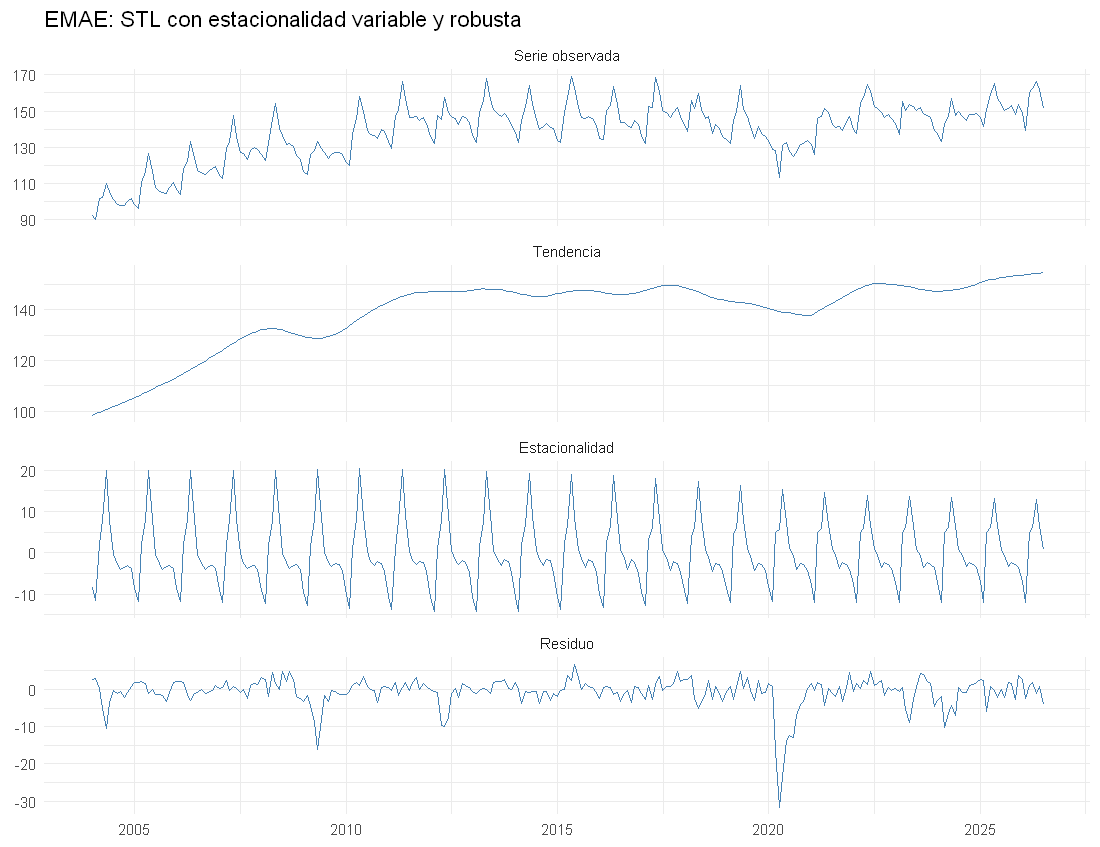

In [23]:
options(repr.plot.height = 7.7)
comp <- desc_stl_flex$time.series
graficar_componentes(emae$fecha,
                     as.numeric(emae_ts),
                     as.numeric(comp[, "trend"]),
                     as.numeric(comp[, "seasonal"]),
                     as.numeric(comp[, "remainder"]),
                     "EMAE: STL con estacionalidad variable y robusta")

Con `robust = TRUE`, STL le asigna a cada observación un **peso** entre 0 y 1. Los meses con peso bajo son los que el método trató como atípicos:

In [24]:
emae |>
  mutate(peso = desc_stl_flex$weights) |>
  arrange(peso) |>
  select(fecha, emae, peso) |>
  head(10)

fecha,emae,peso
<date>,<dbl>,<dbl>
2004-05-01,109.8775,0
2009-05-01,133.0357,0
2012-04-01,145.5203,0
2012-05-01,157.4042,0
2020-03-01,128.2111,0
2020-04-01,113.2950,0
2020-05-01,131.0296,0
2020-06-01,132.5220,0
2020-07-01,127.4637,0


> 💡 **Lectura.** Quedan con peso cero los meses de la pandemia (desde marzo de 2020) y algunos meses de cosecha (mayo de 2004 y 2009, abril y mayo de 2012), cuando el pico agrícola se apartó mucho del habitual. Gracias a eso, esos shocks no deforman ni la tendencia ni los factores estacionales: quedan en el residuo, que es donde tienen que estar.

## 4.3 Comparar las estacionalidades

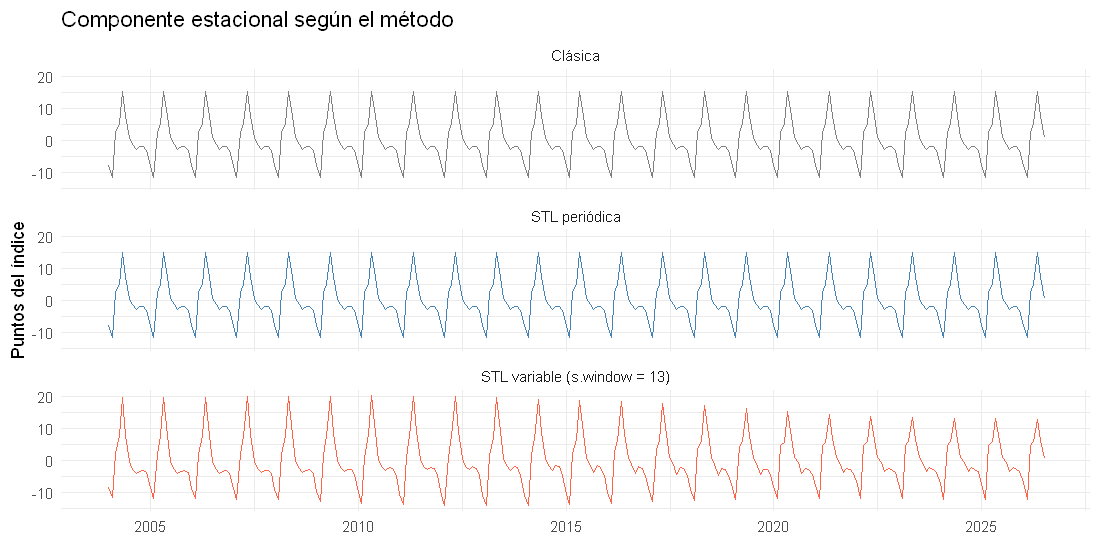

In [25]:
options(repr.plot.height = 4.95)
tibble(fecha = emae$fecha,
       `Clásica` = as.numeric(desc_aditiva$seasonal),
       `STL periódica` = as.numeric(desc_stl$time.series[, "seasonal"]),
       `STL variable (s.window = 13)` = as.numeric(desc_stl_flex$time.series[, "seasonal"])) |>
  pivot_longer(-fecha, names_to = "metodo", values_to = "estacional") |>
  mutate(metodo = fct_inorder(metodo)) |>
  ggplot(aes(fecha, estacional, color = metodo)) +
  geom_line(linewidth = 0.4) +
  facet_wrap(~metodo, ncol = 1) +
  scale_color_manual(values = c("grey50", "steelblue", "tomato")) +
  labs(title = "Componente estacional según el método",
       x = NULL, y = "Puntos del índice") +
  theme(legend.position = "none")

> 💡 **Lectura.** La clásica y la STL periódica repiten el mismo dibujo los 22 años. La STL con `s.window = 13` deja que el patrón **cambie**: el pico de mayo llega a unos 20 puntos entre 2008 y 2013 y baja a unos 13 en los últimos años. Es lo mismo que vimos en la tabla de amplitudes de la Parte 1.3.

# Parte 5. Desestacionalización

¿Para qué desestacionalizar? Comparar un mes con el mismo mes del año anterior es fácil, pero para saber si la actividad **subió de junio a julio** hay que separar lo que es calendario (julio siempre cae) de lo que es cambio genuino. La serie desestacionalizada (SA, *seasonally adjusted*) es la original sin el componente estacional; la **ciclo-tendencia**, además, no tiene ruido.

## 5.1 Factores estacionales "a mano"

Es la versión multiplicativa de la descomposición clásica, paso a paso:

1. Tendencia con MA-12 centrado (ya la tenemos: `ma12`).
2. Ratio $Y_t / \hat T_t$ para cada mes.
3. Promedio de los ratios de cada mes → factor estacional $\hat S_{\text{mes}}$, normalizado para que promedie 1.
4. Serie desestacionalizada: $Y_t^{SA} = Y_t / \hat S_{\text{mes}}$.

In [26]:
factores <- emae |>
  mutate(mes = month(fecha), ratio = emae / ma12) |>
  filter(!is.na(ratio)) |>
  group_by(mes) |>
  summarise(factor = mean(ratio)) |>
  mutate(factor = factor / mean(factor))

factores |> mutate(mes = month.abb[mes])

mes,factor
<chr>,<dbl>
Jan,0.9426919
Feb,0.9160975
Mar,1.0170713
Apr,1.0371349
May,1.1118044
Jun,1.0536840
Jul,1.0064470
Aug,0.9896754
Sep,0.9781592


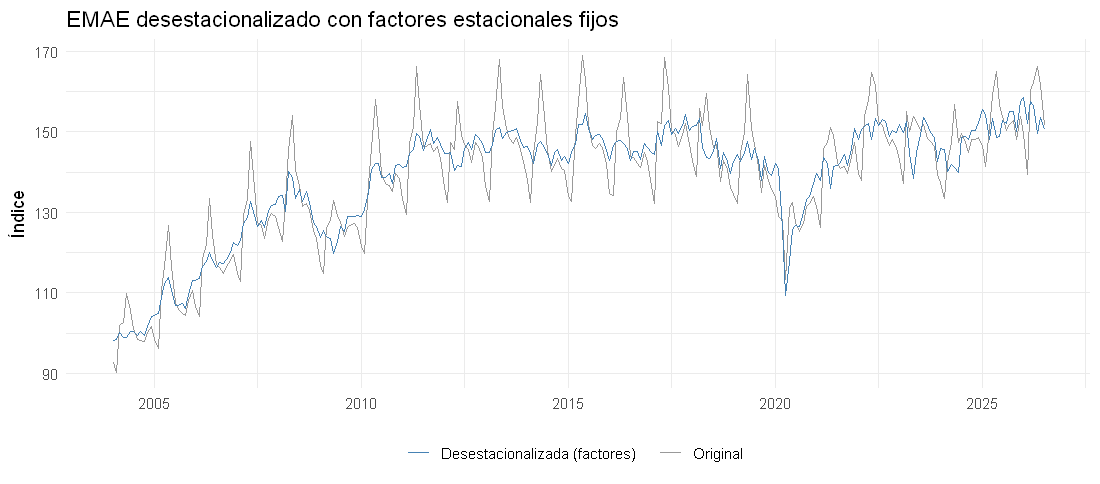

In [27]:
options(repr.plot.height = 4.4)
emae <- emae |>
  mutate(mes = month(fecha)) |>
  left_join(factores, by = "mes") |>
  mutate(emae_sa_manual = emae / factor)

ggplot(emae, aes(fecha)) +
  geom_line(aes(y = emae, color = "Original"), linewidth = 0.3) +
  geom_line(aes(y = emae_sa_manual, color = "Desestacionalizada (factores)"), linewidth = 0.6) +
  scale_color_manual(values = c("Original" = "grey60", "Desestacionalizada (factores)" = "steelblue")) +
  labs(title = "EMAE desestacionalizado con factores estacionales fijos",
       x = NULL, y = "Índice", color = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** Febrero queda con un factor de 0,92 y mayo de 1,11: para desestacionalizar, al dato de febrero se lo divide por 0,92 (sube un 9%) y al de mayo por 1,11 (baja un 10%). La serie resultante ya no tiene el serrucho, aunque conserva el ruido mes a mes.

## 5.2 Desestacionalización con STL (sobre logaritmos)

Como la estacionalidad del EMAE es multiplicativa (Parte 1.3), aplicamos STL al **logaritmo** de la serie, le restamos el componente estacional y volvemos a niveles con `exp()`:

$$\log Y_t^{SA} = \log Y_t - \hat S_t \quad\Rightarrow\quad Y_t^{SA} = \exp(\log Y_t - \hat S_t)$$

In [ ]:
stl_log <- stl(log(emae_ts), s.window = 13, t.window = 25, robust = TRUE)

emae <- emae |>
  mutate(emae_sa_stl = exp(as.numeric(log(emae_ts) - stl_log$time.series[, "seasonal"])),
         emae_tc_stl = exp(as.numeric(stl_log$time.series[, "trend"])))

## 5.3 Comparación con la serie oficial del INDEC (X-13ARIMA-SEATS)

El INDEC desestacionaliza con **X-13ARIMA-SEATS**, el método estándar internacional: además de la estacionalidad, corrige efectos de calendario (días hábiles, Semana Santa, años bisiestos) y detecta outliers en forma automática. Veamos qué tan cerca queda nuestra STL.

In [ ]:
options(repr.plot.height = 4.95)
emae |>
  filter(fecha >= "2017-01-01") |>
  select(fecha, Original = emae, `SA INDEC (X-13)` = emae_sa_indec,
         `SA STL (nuestra)` = emae_sa_stl, `Ciclo-tendencia STL` = emae_tc_stl) |>
  pivot_longer(-fecha, names_to = "serie", values_to = "valor") |>
  mutate(serie = fct_inorder(serie)) |>
  ggplot(aes(fecha, valor, color = serie, linewidth = serie)) +
  geom_line() +
  scale_color_manual(values = c("grey75", "black", "steelblue", "tomato")) +
  scale_linewidth_manual(values = c(0.3, 0.5, 0.5, 0.9)) +
  labs(title = "EMAE desestacionalizado: STL vs. INDEC",
       x = NULL, y = "Índice", color = NULL, linewidth = NULL) +
  theme(legend.position = "bottom")

In [ ]:
# ¿Cuánto difieren las variaciones mensuales de las dos series desestacionalizadas?
comparacion_sa <- emae |>
  mutate(var_indec = (emae_sa_indec / lag(emae_sa_indec) - 1) * 100,
         var_stl   = (emae_sa_stl / lag(emae_sa_stl) - 1) * 100,
         var_manual = (emae_sa_manual / lag(emae_sa_manual) - 1) * 100) |>
  filter(!is.na(var_indec))

comparacion_sa |>
  summarise(`Correlación STL - INDEC` = cor(var_stl, var_indec),
            `Correlación factores fijos - INDEC` = cor(var_manual, var_indec),
            `Dif. media absoluta STL (p.p.)` = mean(abs(var_stl - var_indec)),
            `Dif. media absoluta factores fijos (p.p.)` = mean(abs(var_manual - var_indec)))

> 💡 **Lectura.** En niveles, nuestra STL y la serie oficial se ven casi iguales. En **variaciones mensuales**, en cambio, las diferencias son grandes: la correlación es de 0,74 con STL y de 0,70 con factores fijos, y en promedio la variación mensual de nuestra STL difiere de la oficial en 1,3 puntos porcentuales (1,4 con factores fijos). Una variación mensual típica del EMAE es de ese orden, así que el método puede cambiar el **signo** de la lectura de un mes. Buena parte de la diferencia viene de lo que X-13 corrige y STL no: los efectos de calendario (cantidad de días hábiles, Semana Santa).

## 5.4 Las puntas se revisan

La estimación del componente estacional en los **últimos meses** usa menos información (no hay datos "después"). Cuando llegan datos nuevos, esos meses se recalculan. Para verlo, corremos la misma STL con los datos disponibles hasta diciembre de 2024 y la comparamos con la que usa todos los datos.

In [ ]:
emae_hasta_2024 <- window(log(emae_ts), end = c(2024, 12))
stl_2024 <- stl(emae_hasta_2024, s.window = 13, t.window = 25, robust = TRUE)

revision <- tibble(
  fecha = emae$fecha[emae$fecha <= "2024-12-01"],
  `SA con datos hasta dic-2024` = exp(as.numeric(emae_hasta_2024 - stl_2024$time.series[, "seasonal"])),
  `SA con todos los datos` = emae$emae_sa_stl[emae$fecha <= "2024-12-01"]
) |>
  mutate(revision_pct = (`SA con todos los datos` / `SA con datos hasta dic-2024` - 1) * 100)

revision |> filter(fecha >= "2024-07-01")

> 💡 **Lectura.** Julio y agosto de 2024 casi no cambian (menos de 0,05%), pero los últimos meses se mueven más: septiembre se revisa −0,4% y diciembre −0,6% cuando se agregan los datos de 2025 y 2026. Son revisiones del mismo tamaño que una variación mensual. Por eso los análisis de coyuntura basados en el último dato desestacionalizado son **provisorios**, también en las series oficiales.

> ⚠️ **Atención.** Desestacionalizar no es una transformación inocua: depende del método y de sus parámetros, y el dato de hoy puede cambiar mañana. Siempre hay que **decir qué método se usó**. Para publicaciones oficiales se usa X-13; para análisis propio, STL suele alcanzar y es más transparente.

# Parte 6. Empalme de series

Las series largas suelen tener **quiebres**: un nuevo año base, un cambio de encuesta, una nueva clasificación. Para reconstruir una serie larga y coherente se **empalman** los tramos, y para eso hace falta un período de **superposición** (*overlap*) en el que existan los dos.

| Método | Supuesto sobre el quiebre | Fórmula |
|:--|:--|:--|
| Diferencia | Aditivo: la nueva es la vieja más una constante | $X^{\text{emp}}_t = X^{\text{vieja}}_t + d$ |
| Cociente | Multiplicativo: la nueva es proporcional a la vieja | $X^{\text{emp}}_t = X^{\text{vieja}}_t \times r$ |
| Tasas de variación | Se conserva la dinámica de la vieja | $X^{\text{emp}}_{t-1} = X^{\text{emp}}_t \,/\, (X^{\text{vieja}}_t / X^{\text{vieja}}_{t-1})$ |

## 6.1 Dos series con quiebre

Simulamos lo que pasa cuando el INDEC cambia la base de un indicador: partimos el EMAE en una serie "vieja", hasta diciembre de 2015, que mide en una escala 25% menor y con un poco de ruido propio, y una serie "nueva", desde enero de 2012, que es el EMAE original. Como sabemos cuál es la serie verdadera, podemos evaluar cada método.

In [ ]:
options(repr.plot.height = 4.4)
set.seed(19)

empalme <- emae |>
  select(fecha, emae) |>
  mutate(serie_vieja = if_else(fecha <= "2015-12-01",
                               emae * 0.75 * exp(rnorm(n(), 0, 0.01)), NA_real_),
         serie_nueva = if_else(fecha >= "2012-01-01", emae, NA_real_))

ggplot(empalme, aes(fecha)) +
  annotate("rect", xmin = ymd("2012-01-01"), xmax = ymd("2015-12-01"),
           ymin = -Inf, ymax = Inf, alpha = 0.1, fill = "steelblue") +
  geom_line(aes(y = serie_vieja, color = "Serie vieja"), linewidth = 0.5, na.rm = TRUE) +
  geom_line(aes(y = serie_nueva, color = "Serie nueva"), linewidth = 0.5, na.rm = TRUE) +
  annotate("text", x = ymd("2014-01-01"), y = Inf, label = "Overlap",
           vjust = 2, color = "steelblue", fontface = "bold") +
  scale_color_manual(values = c("Serie vieja" = "steelblue", "Serie nueva" = "tomato")) +
  labs(title = "Dos tramos de la misma serie con un quiebre de nivel",
       subtitle = "Zona sombreada: período de superposición (2012-2015)",
       x = NULL, y = "Índice", color = NULL) +
  theme(legend.position = "bottom")

## 6.2 Por diferencia y por cociente

Con los 48 meses de overlap estimamos la **brecha** promedio (para el método aditivo) y el **ratio** promedio (para el multiplicativo). Usar todo el overlap y no un solo mes hace la estimación menos sensible al ruido de un mes en particular.

In [ ]:
overlap <- empalme |> filter(!is.na(serie_vieja), !is.na(serie_nueva))

brecha <- mean(overlap$serie_nueva - overlap$serie_vieja)
ratio  <- mean(overlap$serie_nueva / overlap$serie_vieja)
c(brecha = brecha, ratio = ratio)

empalme <- empalme |>
  mutate(emp_diferencia = coalesce(serie_nueva, serie_vieja + brecha),
         emp_cociente   = coalesce(serie_nueva, serie_vieja * ratio))

`coalesce()` toma el primer valor que no sea `NA`: donde hay serie nueva usa la nueva, y antes de 2012 usa la vieja corregida.

## 6.3 Por tasas de variación

Arrancamos en el punto de empalme (enero de 2012) con el nivel de la serie nueva y vamos **hacia atrás**, mes por mes, dividiendo por la variación de la serie vieja. Como cada valor depende del siguiente, es otro caso para un `for`.

In [ ]:
vieja_hasta_2012 <- empalme |>
  filter(fecha <= "2012-01-01") |>
  arrange(desc(fecha))                       # de enero 2012 hacia atrás

emp_tasas <- numeric(nrow(vieja_hasta_2012))
emp_tasas[1] <- empalme$serie_nueva[empalme$fecha == "2012-01-01"]

for (i in 2:nrow(vieja_hasta_2012)) {
  variacion <- vieja_hasta_2012$serie_vieja[i - 1] / vieja_hasta_2012$serie_vieja[i]
  emp_tasas[i] <- emp_tasas[i - 1] / variacion
}

empalme <- empalme |>
  left_join(tibble(fecha = vieja_hasta_2012$fecha, emp_tasas), by = "fecha") |>
  mutate(emp_tasas = coalesce(serie_nueva, emp_tasas))

## 6.4 Comparar los tres métodos

In [ ]:
options(repr.plot.height = 4.95)
empalme |>
  filter(fecha <= "2013-12-01") |>
  select(fecha, `Verdadera` = emae, Diferencia = emp_diferencia,
         Cociente = emp_cociente, `Tasas de var.` = emp_tasas) |>
  pivot_longer(-fecha, names_to = "metodo", values_to = "valor") |>
  mutate(metodo = fct_inorder(metodo)) |>
  ggplot(aes(fecha, valor, color = metodo, linetype = metodo)) +
  geom_line(linewidth = 0.5) +
  scale_color_manual(values = c("grey30", "darkorange", "steelblue", "forestgreen")) +
  scale_linetype_manual(values = c("dashed", "solid", "solid", "solid")) +
  labs(title = "Serie empalmada según el método, 2004-2013",
       x = NULL, y = "Índice", color = NULL, linetype = NULL) +
  theme(legend.position = "bottom")

In [ ]:
# Error de cada método en el tramo reconstruido (antes de 2012)
empalme |>
  filter(fecha < "2012-01-01") |>
  pivot_longer(c(emp_diferencia, emp_cociente, emp_tasas),
               names_to = "metodo", values_to = "valor") |>
  group_by(metodo) |>
  summarise(error_medio_pct = mean((valor / emae - 1) * 100),
            error_abs_medio_pct = mean(abs(valor / emae - 1) * 100),
            valor_ene_2004 = valor[fecha == "2004-01-01"]) |>
  bind_rows(tibble(metodo = "verdadero", valor_ene_2004 = emae$emae[1]))

> 💡 **Lectura.** El quiebre que simulamos es multiplicativo, así que el método por **diferencia** es el que peor anda: le suma 36 puntos a una serie que en 2004 valía unos 70, y deja enero de 2004 en 104,8 cuando el valor verdadero es 92,6 (un error medio de 4,9%, que crece cuanto más atrás se va). Además achata la estacionalidad: suma la misma constante en el pico y en el valle. **Cociente** y **tasas de variación** quedan, en promedio, a alrededor de 1% del valor verdadero (0,9% y 1,1%). Las tasas de variación son, en el fondo, un empalme por cociente que usa el ratio de **un solo mes** (el de empalme); el cociente promedio usa los 48 meses del overlap.

> ⚠️ **Atención.** No hay un método correcto en general: la elección depende del **supuesto sobre el quiebre**. Si un cambio metodológico cambia la escala (índices, series positivas con crecimiento), cociente o tasas. Si suma o resta una cantidad fija (y la serie no tiene mucha tendencia), diferencia. Siempre conviene mirar el gráfico de la serie empalmada buscando saltos en el punto de unión.

# Parte 7. Datos faltantes e interpolación

Antes de completar un dato faltante hay que preguntarse **por qué falta**. Si falta al azar (un sensor que falló, un mes sin relevar), interpolar es razonable. Si falta por una razón estructural (no existía la encuesta, el mercado estaba cerrado), interpolar es inventar una dinámica que no existió. Y no es lo mismo **interpolar** (llenar un hueco entre dos datos conocidos) que **extrapolar** (estimar fuera del rango observado), que tiene mucha más incertidumbre.

| Método | Supuesto | Cuándo usarlo | Problema |
|:--|:--|:--|:--|
| LOCF | El valor no cambia hasta la próxima observación | Stocks y precios regulados (salario mínimo, tasa de política) | Escalones artificiales |
| Lineal | Cambio constante en **niveles** | Gaps cortos, serie suave | Ignora curvatura y estacionalidad |
| Exponencial | Tasa de crecimiento constante (lineal sobre el log) | Población, variables con crecimiento proporcional | No capta aceleraciones |
| Spline cúbico | La serie es suave (curvatura continua) | Series suaves, gaps moderados | Puede **pasarse** (*overshoot*) con gaps largos |
| Stineman | Respeta la monotonía local | Cambios de dirección abruptos | Menos difundido |

## 7.1 Población entre censos

Tenemos un dato cada 10 años aproximadamente, con un hueco de 33 años entre 1914 y 1947. Armamos una grilla con todos los años y la completamos con cada método.

In [ ]:
interp <- tibble(anio = seq(min(censos$anio), max(censos$anio))) |>
  left_join(censos, by = "anio") |>
  mutate(
    locf        = na.locf(poblacion),
    lineal      = approx(censos$anio, censos$poblacion, xout = anio)$y,
    exponencial = exp(approx(censos$anio, log(censos$poblacion), xout = anio)$y),
    spline      = spline(censos$anio, censos$poblacion, xout = anio, method = "natural")$y,
    stineman    = stinterp(censos$anio, censos$poblacion, xout = anio)$y
  )

interp |> filter(anio %in% c(1914, 1920, 1930, 1940, 1947))

In [ ]:
options(repr.plot.height = 4.95)
interp_largo <- interp |>
  pivot_longer(locf:stineman, names_to = "metodo", values_to = "pob") |>
  mutate(metodo = factor(metodo,
    levels = c("locf", "lineal", "exponencial", "spline", "stineman"),
    labels = c("LOCF", "Lineal", "Exponencial", "Spline cúbico", "Stineman")))

interp_largo |>
  filter(anio >= 1895, anio <= 1960) |>
  ggplot(aes(anio, pob / 1e6, color = metodo)) +
  geom_line(linewidth = 0.7) +
  geom_point(data = censos |> filter(anio >= 1895, anio <= 1960),
             aes(anio, poblacion / 1e6), color = "black", size = 2.5, inherit.aes = FALSE) +
  labs(title = "Población entre censos, 1895-1960",
       subtitle = "Puntos negros: censos. El hueco 1914-1947 es el más exigente",
       x = NULL, y = "Millones de habitantes", color = NULL) +
  theme(legend.position = "bottom")

> 💡 **Lectura.** Para 1930, en medio del hueco más largo, los métodos dan entre 7,9 millones (LOCF, que repite el censo de 1914) y 11,8 millones (lineal). La exponencial da 11,1 millones, con una tasa de crecimiento constante de 2,1% anual: es el supuesto más razonable para una población. El spline y Stineman quedan entre las dos (11,5 millones). La diferencia entre métodos llega a 700.000 personas sin contar el LOCF, que con un hueco de 33 años es directamente inservible.

## 7.2 Un hueco artificial en el EMAE

En una serie mensual con estacionalidad, el problema es otro. Le sacamos seis meses al EMAE (abril a septiembre de 2017) y probamos recuperarlos. Como conocemos los valores verdaderos, podemos medir el error.

In [ ]:
emae_gap <- emae |>
  filter(fecha >= "2015-01-01", fecha <= "2019-12-01") |>
  select(fecha, emae) |>
  mutate(es_gap = fecha >= "2017-04-01" & fecha <= "2017-09-01",
         emae_obs = if_else(es_gap, NA_real_, emae))

t_num <- as.numeric(emae_gap$fecha)
obs   <- !emae_gap$es_gap

emae_gap <- emae_gap |>
  mutate(locf     = na.locf(emae_obs),
         lineal   = approx(t_num[obs], emae_obs[obs], xout = t_num)$y,
         spline   = spline(t_num[obs], emae_obs[obs], xout = t_num, method = "natural")$y,
         stineman = stinterp(t_num[obs], emae_obs[obs], xout = t_num)$y)

In [ ]:
options(repr.plot.height = 4.95)
emae_gap |>
  filter(fecha >= "2016-07-01", fecha <= "2018-06-01") |>
  pivot_longer(c(emae, locf, lineal, spline, stineman), names_to = "serie", values_to = "valor") |>
  mutate(serie = factor(serie, levels = c("emae", "locf", "lineal", "spline", "stineman"),
                        labels = c("Verdadera (oculta)", "LOCF", "Lineal", "Spline", "Stineman"))) |>
  ggplot(aes(fecha, valor, color = serie, linetype = serie)) +
  annotate("rect", xmin = ymd("2017-03-15"), xmax = ymd("2017-09-15"),
           ymin = -Inf, ymax = Inf, alpha = 0.1, fill = "tomato") +
  geom_line(linewidth = 0.6) +
  scale_color_manual(values = c("grey30", "darkorange", "steelblue", "forestgreen", "purple")) +
  scale_linetype_manual(values = c("dashed", "solid", "solid", "solid", "solid")) +
  labs(title = "Interpolación de un hueco de 6 meses en el EMAE",
       subtitle = "Zona sombreada: datos faltantes",
       x = NULL, y = "Índice", color = NULL, linetype = NULL) +
  theme(legend.position = "bottom")

In [ ]:
# Error absoluto medio en los meses del hueco, en % del valor verdadero
emae_gap |>
  filter(es_gap) |>
  summarise(across(c(locf, lineal, spline, stineman),
                   \(x) mean(abs(x / emae - 1)) * 100))

> 💡 **Lectura.** Todos los métodos fallan por mucho: el error medio va de 3,2% (Stineman) a 7,5% (spline), cuando una variación mensual típica del EMAE es de 1% o 2%. El motivo es que el hueco cae justo sobre el **pico estacional** de abril-mayo, y ninguno de estos métodos sabe que existe la estacionalidad: LOCF, lineal y Stineman unen marzo con octubre casi en línea recta y se pierden el pico. El spline inventa un pico más alto que el verdadero (*overshoot*) porque prolonga la fuerte suba de febrero a marzo.

> ⚠️ **Atención.** En series con estacionalidad, una alternativa mejor es interpolar la serie **desestacionalizada** y volver a sumarle (o multiplicarle) el factor estacional del mes. Y si la variable es de baja frecuencia (anual) y se la quiere llevar a alta frecuencia (trimestral o mensual), se usan métodos con un **indicador auxiliar** (Denton, Chow-Lin) que distribuyen el total anual siguiendo la dinámica de otra serie.

# Cierre

| Tema | Función en R | Idea para llevarse |
|:--|:--|:--|
| Objeto serie | `ts(x, start, frequency)` | Necesita datos ordenados y sin huecos |
| Cambio de base | `x / x[base] * 100` | Cambia el nivel, no la dinámica |
| Deflactación | `nominal / ipc * 100` | Mismo período y deflactor coherente con la variable |
| Variaciones | `lag(x)`, `lag(x, 12)` | Las interanuales neutralizan la estacionalidad; las variaciones % no se suman |
| Promedios móviles | `rollmean()`, EMA con `for` | Centrado para fechar, trailing para tiempo real; MA-12 elimina estacionalidad |
| Descomposición | `decompose()`, `stl()` | STL permite estacionalidad variable y es robusta a outliers |
| Desestacionalización | `stl()` sobre `log()` | Depende del método y se revisa en las puntas |
| Empalme | `coalesce()`, `for` hacia atrás | El supuesto sobre el quiebre define el método |
| Interpolación | `na.locf()`, `approx()`, `spline()`, `stinterp()` | Primero preguntarse por qué falta el dato |